# 06 Market context

**The question.** Before bids open, what is the market likely to do on this contract? How far below (or above) the engineer's estimate will the low bid land, and how many contractors will bid?

**What we did.** Each contract with a bid summary and an engineer's estimate is one row: **464** opened before 2024 and **208** after (the test). The models see only what is known before bids open (decision D-049): the engineer's estimate, working days, number of items, place, time of year, type of work, the **plan-holder count** (contractors who took out the plans, which Caltrans publishes), and how the market behaved over the previous 12 months. Each method is refreshed every quarter, as in notebook 05. Three methods are compared: Kumo Tabular (which also gives a range), a simple linear model, and the trailing 12-month median.

**What we found.**
- On test contracts the low bid averaged **12.7% below** the engineer's estimate, with a wide spread from contract to contract.
- **Spread:** Kumo misses by **15.7 points** on average, against 17.0 for the median and 18.3 for the linear model. Its 80% range held the actual spread on **76.9%** of test contracts, but a typical range is about **50 points wide**: for a single contract, the range matters more than the middle number.
- **Bidders:** Kumo misses by **1.33 bidders** on average (median 1.79, linear 1.50) and is within one bidder on 63.5% of contracts. Its range held the actual count on 81.7%.
- The plan-holder count carries much of the bidder prediction: without it, Kumo's miss grows to 1.60 bidders.

The full report: [`outputs/15_market_context/`](../outputs/15_market_context/README.md).

## Setup

This loads the project's own code (`src/bidlens/analysis/stages.py`), which reads the results each stage already saved in `outputs/` (decision D-070). Nothing is recomputed here, so the notebook runs in seconds on a fresh copy of the repository, with no database and no model downloads.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)  # run from the project root

import matplotlib.pyplot as plt
import pandas as pd

from bidlens.analysis import stages as s

pd.set_option("display.max_colwidth", 140)
plt.rcParams["figure.max_open_warning"] = 0

## Scores on the test contracts

*Typical miss* is the average distance from the actual value: in points of the engineer's estimate for the spread, in bidders for the count.

In [2]:
s.market_scores()

,Method,Spread: typical miss (points),Spread: within 10 points,Bidders: typical miss,Bidders: within 1
0,Kumo Tabular,15.7,41.8%,1.33,63.5%
1,Linear model,18.3,33.2%,1.50,58.2%
2,Trailing 12-month median,17.0,36.5%,1.79,50.5%
3,"Kumo Tabular, without plan holders",16.4,38.9%,1.60,52.4%
4,"Linear model, without plan holders",18.5,34.1%,1.73,50.0%


## Where the low bid lands against the engineer's estimate

Each dot is one test contract: Kumo's expected spread (across) against the actual one (up). Dots on the dashed line were predicted exactly. The cloud is wide: the method gets the direction and the typical level right, but individual contracts swing by tens of points. Orange dots fell outside the 80% range.

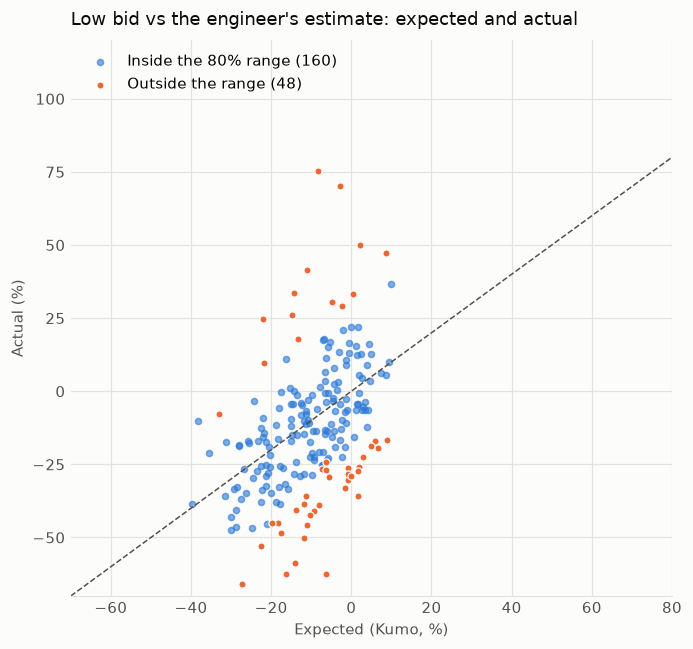

In [3]:
pred = s.market_predictions()
fig = s.chart_spread(pred)
s.save(fig, "spread_expected_vs_actual", s.S15)
plt.show()

## How many bidders

Each circle is a combination of expected and actual bidders; its size is the number of contracts. Most contracts fall within one bidder of the expectation.

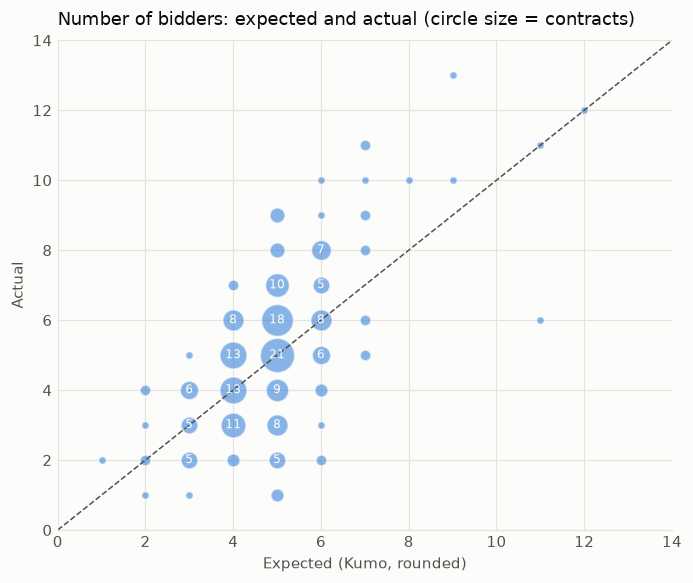

In [4]:
fig = s.chart_bidders(pred)
s.save(fig, "bidders_expected_vs_actual", s.S15)
plt.show()

## The five latest test contracts

The first row is the sample bid package used in notebook 07 and in the app (04-0W0504). Kumo expected the low bid about 19% under the estimate, with a range of 39% under to 2% over; it came in 38% under, just inside the range.

In [5]:
s.market_examples(pred)

,Contract,Bid date,Engineer's estimate,Expected low bid vs EE (80% range),Actual,Expected bidders (range),Actual bidders
203,04-0W0504,2026-09-17,"$22,715,571",-19% (-39% to +2%),-38%,5 (3 to 8),7
204,04-2W6604,2026-09-23,"$2,201,133",-13% (-33% to +9%),+18%,5 (3 to 7),5
205,05-1P2404,2026-09-29,"$791,929",-11% (-34% to +16%),-36%,6 (3 to 8),6
206,04-3AA504,2026-10-07,"$3,549,944",-31% (-52% to -9%),-36%,11 (7 to 14),11
207,05-1Q1504,2026-11-03,"$4,192,092",-24% (-47% to +1%),-30%,6 (4 to 9),4


## Save and next

This adds the charts above to `outputs/15_market_context/`. To recompute (about 15 seconds): `uv run python -m bidlens.market.context`.

**Next:** *07 Document extraction*: reading the bid package itself.

In [6]:
s.note_in_readme(s.S15, "06_market_context.ipynb")
sorted(p.name for p in s.S15.glob("nb_*.png"))

['nb_bidders_expected_vs_actual.png', 'nb_spread_expected_vs_actual.png']